# Gaussian generative models for handwritten digit classification

Recall that the 1-NN classifier yielded a 3.09% test error rate on the MNIST data set of handwritten digits. We will now see that a Gaussian generative model does pretty well also, while being significantly faster and more compact.

## 1. Set up notebook and load in data

As usual, we start by importing the required packages and data. For this notebook we will be using the *entire* `MNIST` dataset. The code below defines some helper functions that will load `MNIST` onto your computer.

In [130]:
%matplotlib inline
import matplotlib.pyplot as plt 
import random
import gzip, os
import numpy as np
from tqdm import tqdm
import plotly.express as px
from scipy.stats import multivariate_normal

In [31]:
#
# Code to read in the MNIST data set
# Make sure you have the four gzipped files containing the data
#
k = 10 # number of classes

def load_mnist_images(filename):
    with gzip.open(filename, 'rb') as f:
        data = np.frombuffer(f.read(), np.uint8, offset=16)
    data = data.reshape(-1,784)
    return data

def load_mnist_labels(filename):
    with gzip.open(filename, 'rb') as f:
        data = np.frombuffer(f.read(), np.uint8, offset=8)
    return data

Now load in the training set and test set

In [32]:
## Load the training set
train_data = load_mnist_images('train-images-idx3-ubyte.gz')
train_labels = load_mnist_labels('train-labels-idx1-ubyte.gz')

## Load the test set
test_data = load_mnist_images('t10k-images-idx3-ubyte.gz')
test_labels = load_mnist_labels('t10k-labels-idx1-ubyte.gz')

The function **displaychar** shows a single MNIST digit. To do this, it first has to reshape the 784-dimensional vector into a 28x28 image.

In [ ]:
def displaychar(image):
    plt.imshow(np.reshape(image, (28,28)), cmap=plt.cm.gray)
    plt.axis('off')
    plt.show()

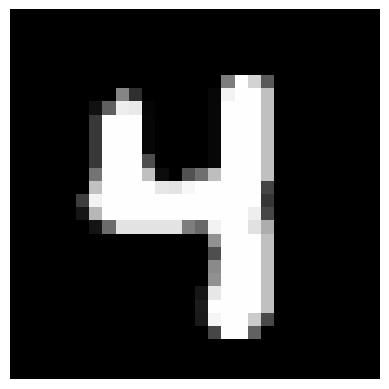

In [34]:
displaychar(train_data[58])

The training set consists of 60,000 images. Thus `train_data` should be a 60000x784 array while `train_labels` should be 60000x1. Let's check.

In [35]:
train_data.shape, train_labels.shape

((60000, 784), (60000,))

In [122]:
test_data.shape, test_labels.shape

((10000, 784), (10000,))

## 2. Fit a Gaussian generative model to the training data

**<font color="magenta">For you to do:</font>** Define a function, **fit_generative_model**, that takes as input a training set (data `x` and labels `y`) and fits a Gaussian generative model to it. It should return the parameters of this generative model; for each label `j = 0,1,...,9`, we have:
* `pi[j]`: the frequency of that label
* `mu[j]`: the 784-dimensional mean vector
* `sigma[j]`: the 784x784 covariance matrix

This means that `pi` is 10x1, `mu` is 10x784, and `sigma` is 10x784x784.

We have already seen how to fit a Gaussian generative model in the Winery example, but now there is an added ingredient. <font color="magenta">The empirical covariances are very likely to be singular (or close to singular), which means that we won't be able to do calculations with them</font>. Thus it is important to **regularize** these matrices. The standard way of doing this is to add `cI` to them, where `c` is some constant and `I` is the 784-dimensional identity matrix. (To put it another way, we compute the empirical covariances and then increase their diagonal entries by some constant `c`.)

This modification is guaranteed to yield covariance matrices that are non-singular, for any `c > 0`, no matter how small. But this doesn't mean that we should make `c` as small as possible. Indeed, `c` is now a parameter, and by setting it appropriately, we can improve the performance of the model. We will study **regularization** in greater detail over the coming weeks.

Your routine needs to choose a good setting of `c`. Crucially, this needs to be done using the training set alone. So you might try setting aside part of the training set as a validation set, or using some kind of cross-validation.

In [111]:
def fit_generative_model(x, y):
    mu = np.array([np.mean(x[y == i], axis=0) for i in range(0, k)])
    sigma = np.array([np.cov(x[y == i].T) for i in range(0, k)])
    _, counts = np.unique(y, return_counts=True)
    pi = counts / float(len(x))
    return mu, sigma, pi

Okay, let's try out your function. In particular, we will use **displaychar** to visualize the means of the Gaussians for the first three digits. You can try the other digits on your own.

In [113]:
mu, sigma, pi = fit_generative_model(train_data, train_labels)
# print(sigma.shape)
# displaychar(mu[0])
# displaychar(mu[1])
# displaychar(mu[2])

In [108]:
# for i in range(0,k):
#     displaychar(sigma[i].diagonal())

## 3. Make predictions on test data

Now let's see how many errors your model makes on the test set.

In [ ]:
def score(mu, sigma, pi):
    score = np.zeros((len(test_labels), k))
    for label in range(k):
        rv = multivariate_normal(mean=mu[label], cov=sigma[label])
        for i in range(len(test_labels)):
            score[i, label] = np.log(pi[label]) + rv.logpdf(test_data[i, :])
    predictions = np.argmax(score, axis=1)
    error = np.mean(predictions != test_labels)
    return error

error_rates = []
cs = [1000*i for i in range(1, 11)]
mu, sigma, pi = fit_generative_model(train_data, train_labels)

for c in tqdm(cs):
    sigma_c = [s + c * np.eye(s.shape[0]) for s in sigma]
    error = score(mu, sigma_c, pi)
    error_rates.append(error)

100%|██████████| 10/10 [06:55<00:00, 41.53s/it]


In [124]:
px.line(x=cs, y=error_rates)

In [129]:
sigma_c = [s + 4000 * np.eye(s.shape[0]) for s in sigma]
score = np.zeros((len(test_labels), k))
for label in range(k):
    rv = multivariate_normal(mean=mu[label], cov=sigma_c[label])
    for i in range(len(test_labels)):
        score[i, label] = np.log(pi[label]) + rv.logpdf(test_data[i, :])
predictions = np.argmax(score, axis=1)

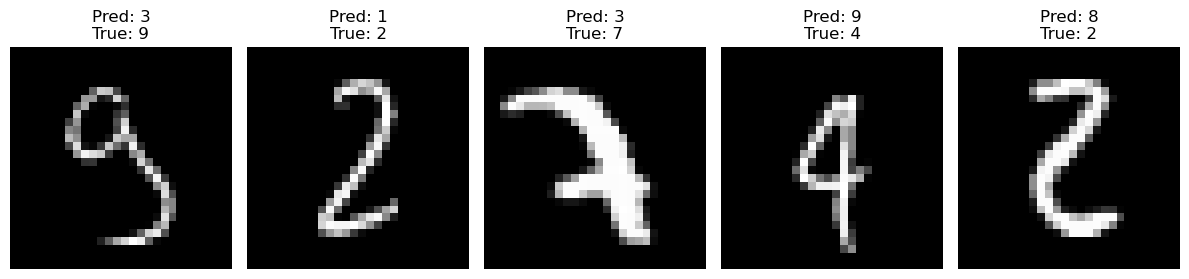

In [137]:
misclassified_indices = np.where(predictions != test_labels)[0]
chosen_indices = np.random.choice(misclassified_indices, size=5, replace=False)

fig, axs = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    idx = chosen_indices[i]
    axs[i].imshow(test_data[idx].reshape(28, 28), cmap=plt.cm.gray)
    axs[i].axis('off')
    axs[i].set_title(f'Pred: {predictions[idx]}\nTrue: {test_labels[idx]}')

plt.tight_layout()
plt.show()


## 4. Things to ponder

* What happens if you do not regularize the covariance matrices?
* What happens if you set the value of `c` too high, for instance to one billion? Do you understand why this happens?
* What value of c did you end up using? How many errors did your model make on the training set?
* We have talked about using the same regularization constant `c` for all ten classes. What about using a different value of `c` for each class? How would you go about choosing these? Can you get better performance in this way?